<a href="https://colab.research.google.com/github/yabasahilda2004/Bakery_Sales/blob/main/bakery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IMPORTING LIBRARIES

Libraries used throughout the project: `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for visualization, and `scikit-learn` for modelling.

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


## DATA LOADING

The bakery dataset (`bakery_sales_dataset.csv`) is loaded into a DataFrame. A first look at its shape, column names, data types and sample rows gives us an overview.

In [42]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Bakery_sales/bakery_sales_dataset.csv")

In [44]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [45]:
df.shape

(19321, 40)

- The dataset has an initial 19321 Rows and 40 Columns

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

In [47]:
# Checking for missing values in the dataset
df.isna().sum()

,0
Order_ID,0
Customer_ID,0
Customer_Age,0
Customer_Gender,0
Customer_Segment,0
Loyalty_Member,0
Date,0
Year,0
Month,0
Day,0


- Festival columns has 16006 non festival values
- Promotion_Type column has 13826 no promotion values

In [48]:
# Checking for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

## DATA CLEANING AND VALIDATION

In [49]:
# Filling missing values in 'Festival' and 'Promotion_Type' columns with "None"
df[['Festival', 'Promotion_Type']] = df[['Festival','Promotion_Type']].fillna("None")

- Filled the Blank spaces with "None" to signify there was no festival or promotions at the time

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             19321 non-null 

In [51]:
dict = {}
for i in list(df.columns):
    dict[i] = df[i].value_counts().shape[0]
pd.DataFrame(dict,index=["Unique counts"]).transpose()

,Unique counts
Order_ID,6576
Customer_ID,500
Customer_Age,57
Customer_Gender,3
Customer_Segment,4
Loyalty_Member,2
Date,731
Year,2
Month,12
Day,31


- Converting some columns to categorical data type for better memory usage and performance

In [52]:

cat_cols = ['Customer_Gender','Loyalty_Member','Weekend','Season','Festival', 'Promotion_Type', 'Category','Payment_Method','Promotion_Applied','Storage_Type','Perishability','Customer_Rating']
df[cat_cols] = df[cat_cols].astype('category')

- Converting the 'Date' column to datetime format for easier manipulation and analysis

In [53]:

df['Date'] = pd.to_datetime(df['Date'], format='mixed')

In [54]:
df.shape

(19321, 40)

In [55]:
# Logical checks to look for anomalies in the dataset
checks = {
    'negative quantity':        df['Quantity'] < 0,
    'negative price':           df['Unit_Price'] <= 0,
    'discount outside 0-100':   ~df['Discount_Percentage'].between(0, 100),
    'sold > produced':          df['Units_Sold'] > df['Units_Produced'],
    'cost > unit price':        df['Cost_Price'] > df['Unit_Price'],
    'waste pct outside 0-100':  ~df['Waste_Pct'].between(0, 100),
    'negative stock':           df['Stock_Available'] < 0,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

negative quantity: 0
negative price: 0
discount outside 0-100: 0
sold > produced: 0
cost > unit price: 0
waste pct outside 0-100: 0
negative stock: 0


In [56]:
df.describe()

,Customer_Age,Date,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit
count,19321.000000,19321,19321.000000,19321.000000,19321.000000,19321.00000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000
mean,35.541846,2024-01-05 01:21:45.584597248,2023.508100,6.559184,15.871901,12.86481,26.988127,2.226955,87.263624,49.275521,4.345541,83.372033,139.268467,61.117333,4.221469,3.046788,1.174680,1.131101,34.118715,59.196602
min,16.000000,2023-01-01 00:00:00,2023.000000,1.000000,1.000000,7.00000,8.100000,1.000000,7.600000,3.270000,0.000000,5.680000,13.120000,1.000000,2.000000,1.000000,1.000000,1.000000,4.200000,-0.550000
25%,25.000000,2023-07-13 00:00:00,2023.000000,4.000000,8.000000,9.00000,21.200000,1.000000,31.020000,16.900000,0.000000,30.400000,52.120000,3.000000,2.000000,1.000000,1.000000,1.000000,25.000000,20.690000
50%,34.000000,2024-01-06 00:00:00,2024.000000,7.000000,16.000000,12.00000,27.700000,2.000000,45.090000,23.640000,0.000000,42.660000,82.800000,5.000000,3.000000,2.000000,1.000000,1.000000,33.300000,36.760000
75%,45.000000,2024-07-07 00:00:00,2024.000000,10.000000,24.000000,17.00000,33.200000,3.000000,76.650000,52.640000,7.500000,72.030000,146.540000,82.000000,5.000000,4.000000,1.000000,1.000000,50.000000,65.920000
max,73.000000,2024-12-31 00:00:00,2024.000000,12.000000,31.000000,21.00000,44.900000,20.000000,472.420000,296.280000,30.000000,472.420000,1885.960000,729.000000,49.000000,37.000000,16.000000,20.000000,50.000000,767.600000
std,13.733832,NaN,0.499947,3.478048,8.767930,3.94044,8.813511,1.782968,110.481951,65.969024,6.794384,105.762887,157.772593,103.611553,3.635227,3.038092,0.783283,0.752667,12.734206,65.238370


In [57]:
#Checking the season for which a month falls in
print(pd.crosstab(df['Month'], df['Season']))

Season  Autumn  Monsoon  Summer  Winter
Month                                  
1            0        0       0    1758
2            0        0       0    1379
3            0        0    1660       0
4            0        0    1658       0
5            0        0    1513       0
6            0     1440       0       0
7            0     1507       0       0
8            0     1560       0       0
9            0     1959       0       0
10        1660        0       0       0
11        1587        0       0       0
12           0        0       0    1640


## FEATURE ENGINEERING

New columns were derived from the cleaned data so that the later analysis, forecasting and dashboards can use them directly.

**Date-based features**
- `month_name`, `year_month`: readable labels for monthly trend charts. `year_month` keeps the same month in different years separate.
- `week_number`, `iso_year`: ISO week numbering. `iso_year` is kept alongside it because dates at the start and end of a year can belong to a neighbouring ISO year.

**Indicator features (1 = yes, 0 = no)**
- `is_weekend`: 1 for Saturday and Sunday. 0 for the weekdays.
- `is_festival`: 1 for any of the 9 listed holidays, 0 when the festival value is "None".

**Financial features**
- `Total_Bill`: quantity × unit price, adjusted for any discount.

Renamed `Total_Bill` to `Revenue`

- `profit_margin`: profit divided by revenue, as a percentage.It is used to compare profitability across products, promotions and stores.

In [58]:
df['month_name'] = df['Date'].dt.month_name()
df['week_number'] = df['Date'].dt.isocalendar().week.astype(int)
df['year_month'] = df['Date'].dt.to_period('M').astype(str)


In [59]:
df['is_weekend'] = df['Day'].isin([1, 7]).astype(int)

In [60]:
print(df['Festival'].value_counts(dropna=False))

Festival
None                16006
Ganesh Chaturthi      967
Diwali                438
Dussehra              298
Eid                   290
Independence Day      286
Christmas             283
Republic Day          278
Holi                  244
New Year              231
Name: count, dtype: int64


In [61]:
df['is_festival'] = (df['Festival'] != 'None').astype(int)

In [62]:
print(df['is_festival'].value_counts(dropna=False))

is_festival
0    16006
1     3315
Name: count, dtype: int64


In [63]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating,month_name,week_number,year_month,is_weekend,is_festival
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,2,2,25.0,141.48,4,January,52,2023-01,1,1
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,1,1,25.0,39.96,4,January,52,2023-01,1,1
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,1,1,33.3,103.83,4,January,52,2023-01,1,1
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,3,2,23.1,79.73,4,January,52,2023-01,1,1
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,1,1,25.0,10.08,4,January,52,2023-01,1,1


In [64]:
#Renaming Total_Bill to Revenue
df = df.rename(columns={'Total_Bill':'Revenue'})

In [65]:
print(df['Revenue'].describe())
print((df['Revenue'] < 0).sum())
print(df['Revenue'].isna().sum())

count    19321.000000
mean       139.268467
std        157.772593
min         13.120000
25%         52.120000
50%         82.800000
75%        146.540000
max       1885.960000
Name: Revenue, dtype: float64
0
0


In [66]:
df['profit_margin'] = df['Profit'] / df['Revenue'] * 100

## APPLICATIONS

1. Exploratory data analysis and sales trend visualization.

This section explores the distribution of key numeric values (Revenue, Quantity and Profit Margin).

It also examines how revenue changes over time (month by month and year over year).

In [67]:
# Summary Statistics
print(df[['Quantity', 'Unit_Price','Selling_Price', 'Revenue', 'Profit', 'profit_margin']].describe())

           Quantity    Unit_Price  Selling_Price       Revenue        Profit  \
count  19321.000000  19321.000000   19321.000000  19321.000000  19321.000000   
mean       2.226955     87.263624      83.372033    139.268467     59.196602   
std        1.782968    110.481951     105.762887    157.772593     65.238370   
min        1.000000      7.600000       5.680000     13.120000     -0.550000   
25%        1.000000     31.020000      30.400000     52.120000     20.690000   
50%        2.000000     45.090000      42.660000     82.800000     36.760000   
75%        3.000000     76.650000      72.030000    146.540000     65.920000   
max       20.000000    472.420000     472.420000   1885.960000    767.600000   

       profit_margin  
count   19321.000000  
mean       43.194202  
std         9.473177  
min        -2.510269  
25%        37.821394  
50%        44.554223  
75%        49.627483  
max        61.984316  


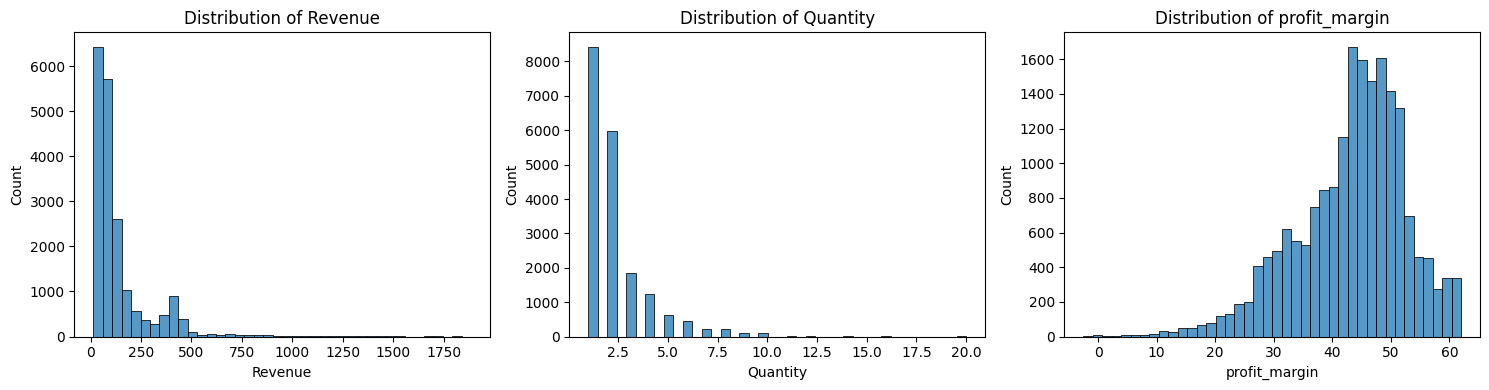

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Revenue', 'Quantity', 'profit_margin']):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

`Revenue` - It is heavily right-skewed. Most sales are small, with the biggest group under 250.

`Quantity` - It is right Skewed .Most sales are 1-3 items.

`profit_margin` - Margins cluster around 40-55%, with a peak near 45-50%, and a tail toward lower values.

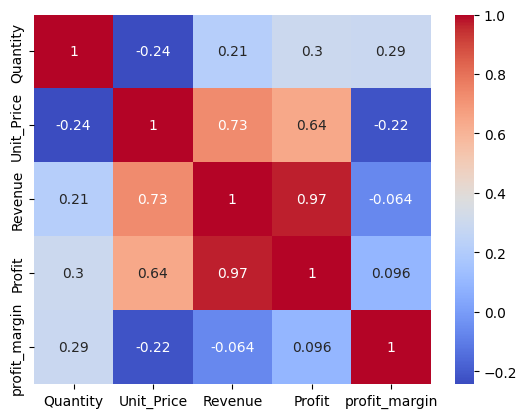

In [69]:
sns.heatmap(df[['Quantity', 'Unit_Price', 'Revenue', 'Profit', 'profit_margin']].corr(), annot=True, cmap='coolwarm')
plt.show()

**Correlation analysis**

The heatmap shows the linear relationship between the main numeric variables.

- **Revenue and Profit (0.97):** almost perfectly correlated. This is expected, because profit is part of each sale's revenue, so it is not an independent finding.

- **Unit price drives revenue more than quantity does.** `Unit_Price` has a strong positive correlation with `Revenue` (0.73) and `Profit` (0.64), while `Quantity` has only a weak one with `Revenue` (0.21) and `Profit` (0.30). Revenue depends more on which product is sold than on how many items are bought.

- **Quantity and unit price are negatively correlated (-0.24):** customers tend to buy cheaper items in larger numbers.

- **Profit margin is largely independent of revenue (-0.06) and profit (0.10).** A bigger sale does not mean a better margin.

- **Margin has weak relationships with the other two variables:** it rises slightly with quantity (0.29) and falls slightly with unit price (-0.22). Cheaper items bought in larger numbers.



**A. What is the Monthly Revenue Trend?**

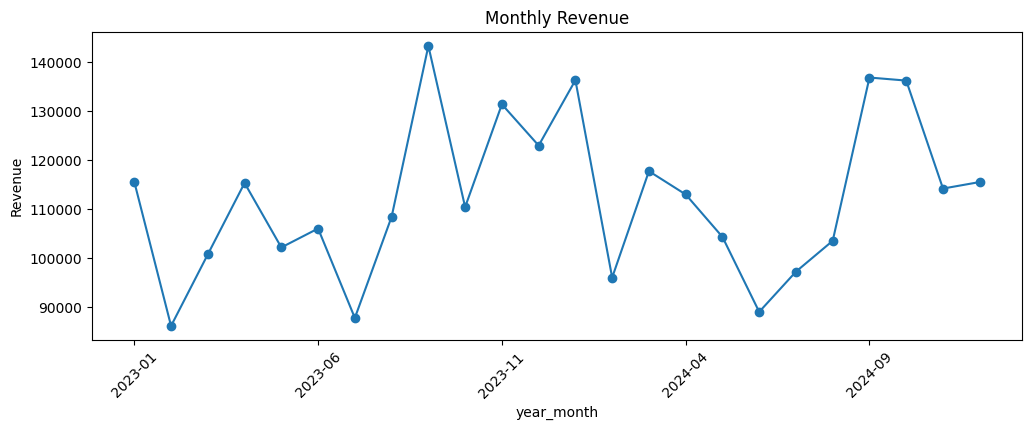

In [70]:
monthly = df.groupby('year_month')['Revenue'].sum()
monthly.plot(figsize=(12,4), marker= 'o', title = 'Monthly Revenue')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

Monthly revenue fluctuates between roughly 86k and 143k. In both years, revenue is lowest in February and in mid-year (June-July) and peaks in September. Late 2023 stayed high through January 2024, whereas in 2024 revenue fell back after October, so the end-of-year rise is not consistent across both years.

In [71]:
monthly.sort_values()

,Revenue
year_month,
2023-02,86207.93
2023-07,87839.27
2024-06,89075.96
2024-02,96067.86
2024-07,97273.15
2023-03,100798.92
2023-05,102209.33
2024-08,103563.62
2024-05,104352.78


**B. What is the comparison in Revenue betweeen 2023 and 2024?**

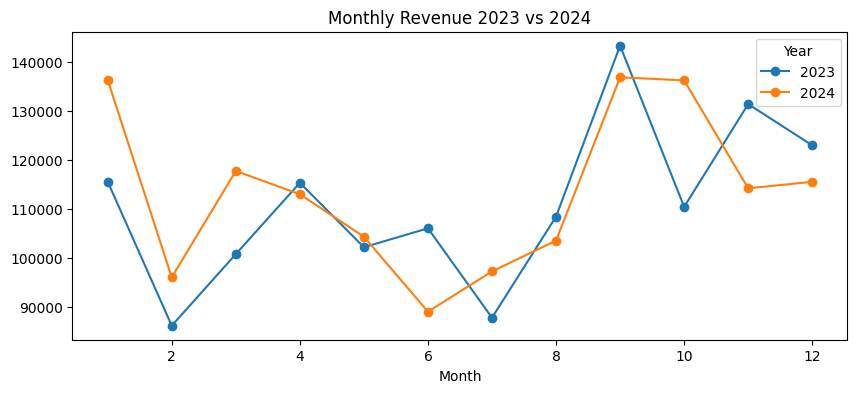

In [72]:
yr_comp = df.pivot_table(index='Month', columns='Year',values='Revenue',aggfunc='sum')
yr_comp.plot(marker='o',figsize=(10,4),title='Monthly Revenue 2023 vs 2024')
plt.show()

Monthly revenue follows a similar seasonal pattern in 2023 and 2024: both years drop in February and mid-year (June-July), then peak in September.

The years differ at the edges: 2024 started much stronger (January) and held up in October, while 2023 was stronger from September to December.

Since Revenue and Profit correlate at 0.97 the charts will be similar and can tell profits in place of revenue.

2. Product-wise, monthly, seasonal, weekend, and festival sales analysis.

In [73]:
# Daily Table setup
daily = df.groupby('Date').agg(
    revenue = ('Revenue', 'sum'),
    units = ('Quantity', 'sum'),
    profit=('Profit', 'sum'),
    is_weekend=('is_weekend', 'max'),
    is_festival=('is_festival', 'max'),
    Festival=('Festival', 'first'),
    Season=('Season', 'first'),
    Month=('Month', 'first'),
).reset_index()

In [75]:
daily.head()

,Date,revenue,units,profit,is_weekend,is_festival,Festival,Season,Month
0,2023-01-01,11808.33,182,4453.00,1,1,New Year,Winter,1
1,2023-01-02,9764.76,120,3760.30,0,1,New Year,Winter,1
2,2023-01-03,2257.85,33,1037.32,0,0,None,Winter,1
3,2023-01-04,4488.55,57,2024.57,0,0,None,Winter,1
4,2023-01-05,2112.90,54,935.97,0,0,None,Winter,1


**A. Product Wise Sales Analysis**

                   units    revenue     profit  margin_pct
Product                                                   
Chocolate Cake       735  291892.80  106223.22   36.391175
Cookies             2440  278419.03  131715.54   47.308383
Black Forest Cake    495  210837.91   76919.95   36.482979
Butterscotch Cake    351  143246.01   55843.18   38.984109
Nankhatai           4743  135692.42   71647.19   52.801173
Chocolate Cookies   1080  134440.17   61403.02   45.673120
Pineapple Cake       351  133266.02   52192.38   39.164057
Tea Cake             808  115511.61   48939.12   42.367274
Puff                3740   89043.31   42316.78   47.523817
Milk                2433   69516.24   18366.73   26.420776


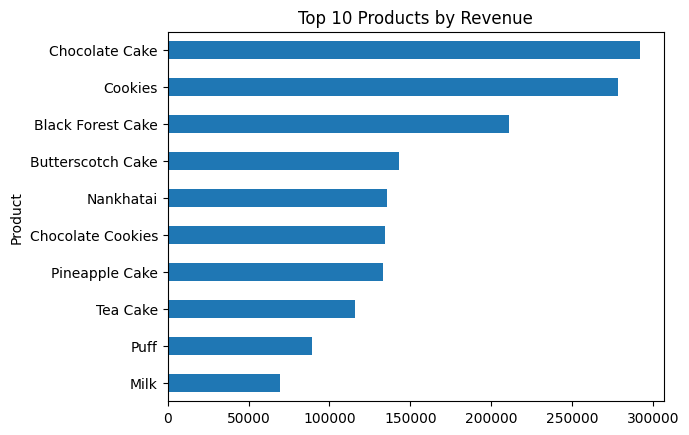

In [76]:
prod = df.groupby('Product').agg(
    units = ('Quantity', 'sum'),
    revenue = ('Revenue','sum'),
    profit = ('Profit', 'sum'),
).sort_values('revenue', ascending=False)
prod['margin_pct']= prod['profit'] / prod['revenue'] * 100
print(prod.head(10))

prod['revenue'].head(10).plot(kind='barh', title = 'Top 10 Products by Revenue').invert_yaxis()
plt.show()

**B. Monthly Sales Analysis**

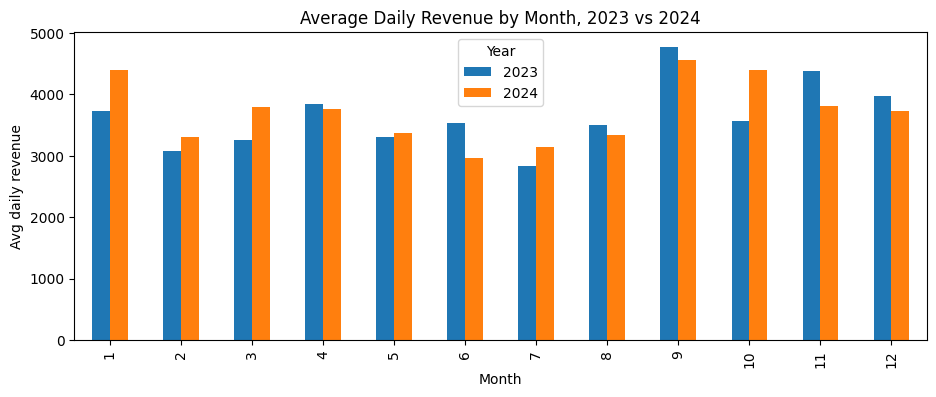

In [78]:
daily['Year'] = daily['Date'].dt.year
by_year = daily.pivot_table(index='Month', columns='Year', values='revenue', aggfunc='mean')
by_year.plot(kind='bar', figsize=(11, 4), title='Average Daily Revenue by Month, 2023 vs 2024')
plt.ylabel('Avg daily revenue')
plt.show()

**C. Seasonal Sales Analysis**

In [79]:
season = daily.groupby('Season').agg(
    avg_daily_revenue = ('revenue', 'mean'),
    avg_daily_units = ('units', 'mean'),
    days = ('Date', 'count'),
)
print(season)

         avg_daily_revenue  avg_daily_units  days
Season                                           
Autumn         4034.887295        60.131148   122
Monsoon        3575.385246        59.569672   244
Summer         3551.498641        55.777174   184
Winter         3716.464365        60.182320   181


/tmp/ipykernel_1266/2108421875.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  season = daily.groupby('Season').agg(


In [80]:
#Product Sales Across Seasons
pd.crosstab(df['Product'], df['Season'], values=df['Quantity'], aggfunc='sum').head(10)

Season,Autumn,Monsoon,Summer,Winter
Product,,,,
Biscuit,340,821,460,573
Black Forest Cake,81,174,118,122
Bread,313,513,422,398
Brown Bread,108,298,191,168
Butter,207,402,295,272
Butterscotch Cake,58,110,101,82
Cheese,136,224,155,155
Chocolate Cake,182,199,167,187
Chocolate Cookies,267,326,238,249


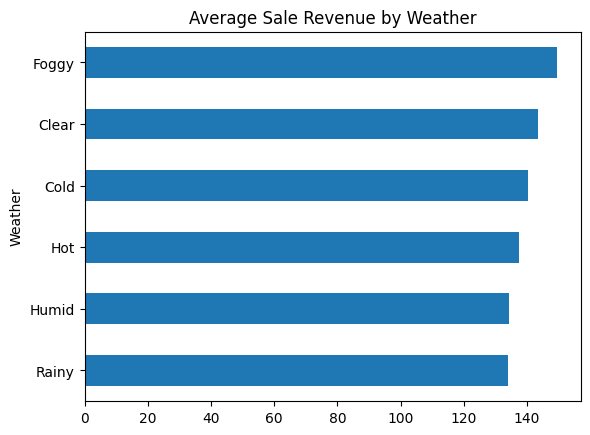

In [81]:
#Revenue distribution across different Weather.
df.groupby('Weather')['Revenue'].mean().sort_values().plot(kind='barh', title='Average Sale Revenue by Weather')
plt.show()

In [82]:
#Product Sales Across Differnt Weather.
pd.crosstab(df['Product'], df['Weather'], values=df['Quantity'], aggfunc='sum').head(10)

Weather,Clear,Cold,Foggy,Hot,Humid,Rainy
Product,,,,,,
Biscuit,579,227,212,261,469,446
Black Forest Cake,133,51,56,59,104,92
Bread,493,200,143,225,325,260
Brown Bread,210,79,52,92,174,158
Butter,373,116,106,133,259,189
Butterscotch Cake,107,45,22,52,64,61
Cheese,167,94,50,92,149,118
Chocolate Cake,208,103,84,91,154,95
Chocolate Cookies,329,153,81,130,193,194
